# Experiment 5: Data Visualization with Matplotlib (AQI)

**A52 Dipanshu Ambilkar**

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [2]:
np.random.seed(4)
dates = pd.date_range("2026-01-01", periods=90)
df = pd.DataFrame({
    "date": dates,
    "pm25": np.random.normal(80, 25, 90).clip(10, 200),
    "pm10": np.random.normal(120, 35, 90).clip(20, 300),
    "co": np.random.normal(1.2, 0.4, 90).clip(0.2, 3),
})
df["aqi"] = (df["pm25"] * 1.2 + df["pm10"] * 0.5).astype(int)
print(df.head())
print(df.describe())

        date       pm25        pm10        co  aqi
0 2026-01-01  81.264043  121.701105  1.288901  158
1 2026-01-02  92.498783  126.602617  1.621440  174
2 2026-01-03  55.102277  127.325972  0.946457  129
3 2026-01-04  97.339963  106.894428  1.051759  170
4 2026-01-05  69.542462  153.414451  1.014582  160
                      date        pm25        pm10         co         aqi
count                   90   90.000000   90.000000  90.000000   90.000000
mean   2026-02-14 12:00:00   80.918911  122.458523   1.221775  157.844444
min    2026-01-01 00:00:00   20.505618   51.189485   0.411299   63.000000
25%    2026-01-23 06:00:00   63.741348  103.431085   1.007870  135.000000
50%    2026-02-14 12:00:00   81.312431  121.526669   1.142707  156.500000
75%    2026-03-08 18:00:00   96.871658  143.381380   1.503508  179.000000
max    2026-03-31 00:00:00  141.914604  197.124741   2.074339  232.000000
std                    NaN   25.418651   32.207356   0.388954   33.402520


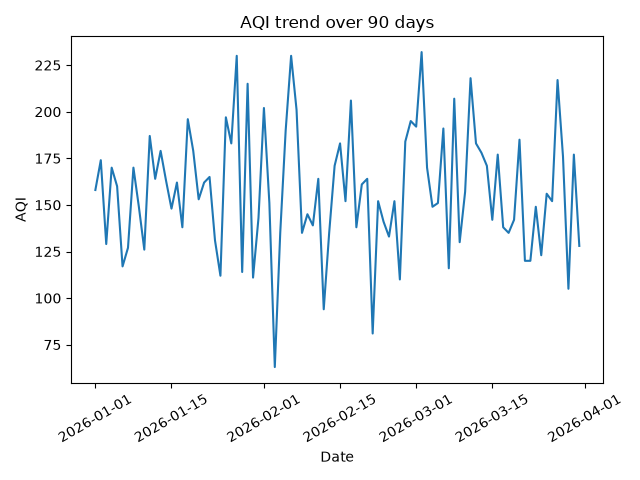

In [3]:
plt.plot(df["date"], df["aqi"])
plt.title("AQI trend over 90 days")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("aqi_trend.png")
display(Image("aqi_trend.png"))
plt.close()

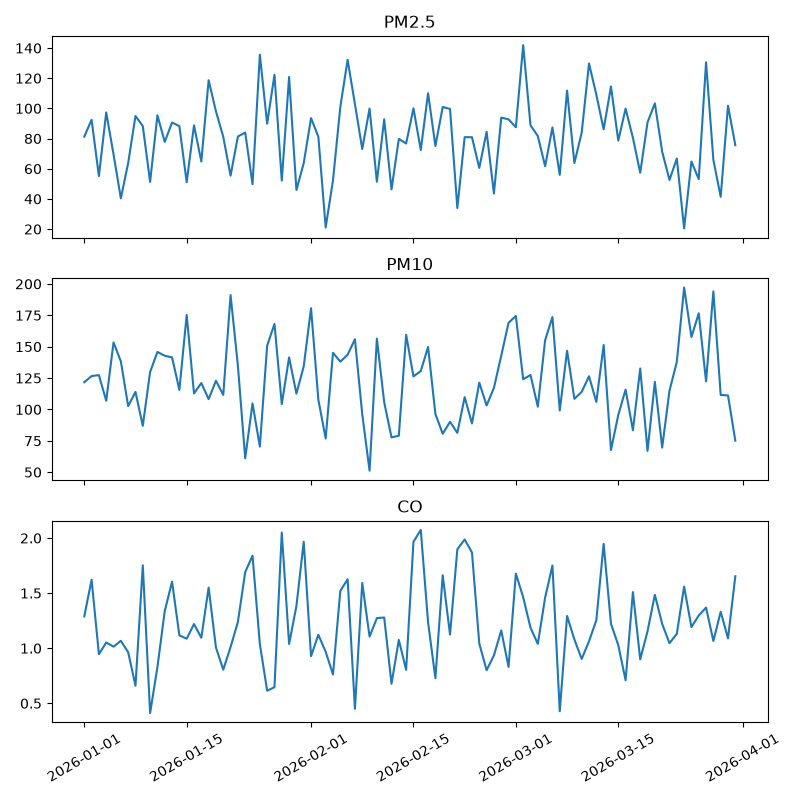

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
ax[0].plot(df["date"], df["pm25"])
ax[0].set_title("PM2.5")
ax[1].plot(df["date"], df["pm10"])
ax[1].set_title("PM10")
ax[2].plot(df["date"], df["co"])
ax[2].set_title("CO")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("pollutants.png")
display(Image("pollutants.png"))
plt.close()

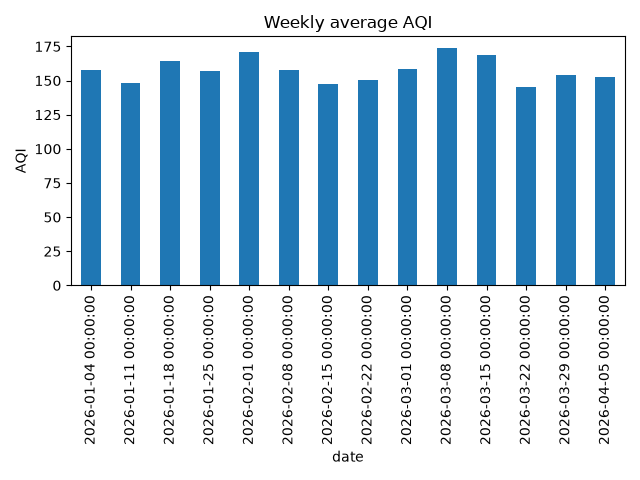

In [5]:
df.set_index("date")["aqi"].resample("W").mean().plot(kind="bar")
plt.title("Weekly average AQI")
plt.ylabel("AQI")
plt.tight_layout()
plt.savefig("aqi_weekly.png")
display(Image("aqi_weekly.png"))
plt.close()

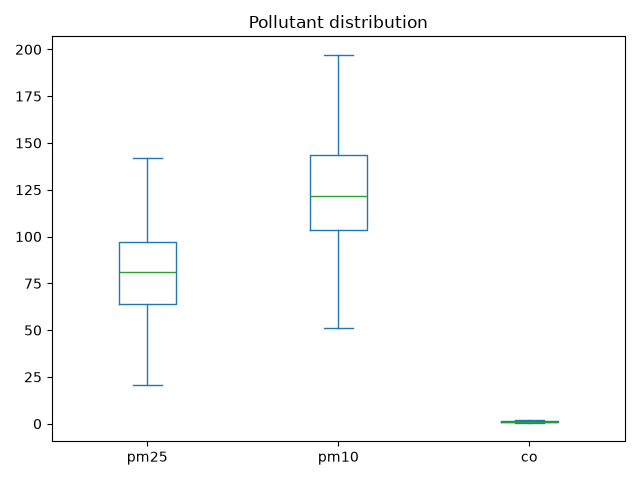

In [6]:
df[["pm25", "pm10", "co"]].plot(kind="box")
plt.title("Pollutant distribution")
plt.tight_layout()
plt.savefig("aqi_box.png")
display(Image("aqi_box.png"))
plt.close()

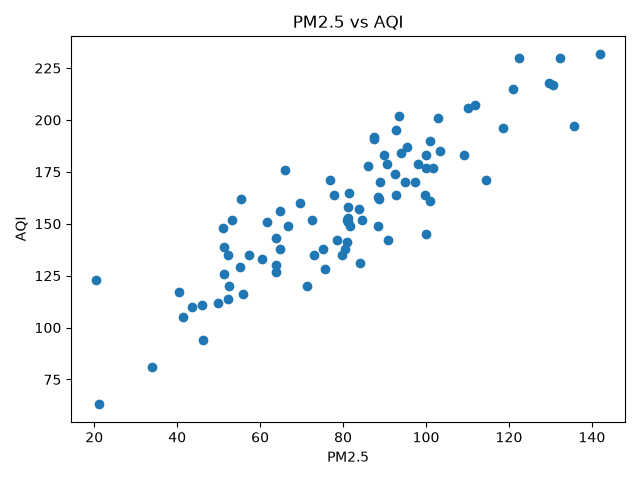

done


In [7]:
plt.scatter(df["pm25"], df["aqi"])
plt.title("PM2.5 vs AQI")
plt.xlabel("PM2.5")
plt.ylabel("AQI")
plt.tight_layout()
plt.savefig("aqi_scatter.png")
display(Image("aqi_scatter.png"))
plt.close()
print("done")